# Lab 01 - Feature Engineering

Notebook này thực thi bước **Feature Engineering** theo `docs/feature-image.md`.
Nó đọc artifact do notebook EDA ghi, đo lại thống kê normalization trên đúng split
đó, và chốt `preprocessing_config.json` để notebook training đọc lại.

Điều kiện tiên quyết: `lab01_eda.ipynb` đã chạy xong. Guard ở phần F0 chặn mọi
trường hợp artifact vắng mặt hoặc không khớp version.

## F0. Guard - kiểm tra điều kiện trước khi tính

Mỗi guard trả về `PASS` hoặc `FAIL`. Guard thất bại được **gom lại** thay vì raise
ngay, để một lần chạy báo được toàn bộ điều kiện chưa đạt. Cuối phần này có một
assert chặn nếu còn guard thất bại.

In [1]:
import sys
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from torchvision import transforms

PROJECT_ROOT = Path("..").resolve()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.config import (
    DATA_DIR, EDA_DIR, CLASS_NAMES, RANDOM_SEED, NUM_CLASSES,
    VAL_SPLIT, SPLIT_VERSION, PREPROC_VERSION, PREPROCESSING_CONFIG_PATH,
)
from src.split import load_split, load_split_metadata
from src import eda as eda_mod
from src.utils import set_seed

TABLES_DIR = EDA_DIR / "tables"
FIGURES_DIR = EDA_DIR / "figures"

set_seed(RANDOM_SEED)
guard_failures = []

def guard(name, condition, detail=""):
    status = "PASS" if condition else "FAIL"
    print(f"[{status}] {name}" + (f" | {detail}" if detail else ""))
    if not condition:
        guard_failures.append(f"{name}: {detail}")
    return condition

print(f"[EDA_DIR] {EDA_DIR}")
print(f"[SPLIT_VERSION] {SPLIT_VERSION} | [PREPROC_VERSION] {PREPROC_VERSION}")

[EDA_DIR] C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda
[SPLIT_VERSION] split_v2_stratified | [PREPROC_VERSION] preproc_v2_train_global_std


In [2]:
required = [
    EDA_DIR / "split_indices.npz",
    EDA_DIR / "split_metadata.json",
    EDA_DIR / "eda_findings.json",
    TABLES_DIR / "integrity_report.csv",
]
for path in required:
    guard(f"artifact exists: {path.name}", path.is_file(), str(path))

split_meta = load_split_metadata(EDA_DIR)
findings = json.loads((EDA_DIR / "eda_findings.json").read_text(encoding="utf-8"))
guard(
    "EDA findings were measured on this split",
    findings["split_version"] == split_meta["split_version"],
    f"{findings['split_version']} vs {split_meta['split_version']}",
)
guard("no guard failed so far", not guard_failures, f"{len(guard_failures)} failure(s)")
assert not guard_failures, f"Guards failed: {guard_failures}"

[PASS] artifact exists: split_indices.npz | C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\split_indices.npz
[PASS] artifact exists: split_metadata.json | C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\split_metadata.json
[PASS] artifact exists: eda_findings.json | C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\eda_findings.json
[PASS] artifact exists: integrity_report.csv | C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\tables\integrity_report.csv
[PASS] EDA findings were measured on this split | split_v2_stratified vs split_v2_stratified
[PASS] no guard failed so far | 0 failure(s)


## F1. Đọc lại split và kiểm tra vẫn đúng

Split được đọc từ artifact, không tạo lại. Kiểm tra số mẫu khớp metadata và hai
partition không chồng lấn.

In [3]:
train_idx, val_idx = load_split(EDA_DIR, expected_pool_size=split_meta["pool_size"])

guard("train size matches metadata", len(train_idx) == split_meta["train_size"],
      f"{len(train_idx)} vs {split_meta['train_size']}")
guard("val size matches metadata", len(val_idx) == split_meta["val_size"],
      f"{len(val_idx)} vs {split_meta['val_size']}")
guard("train/val disjoint", np.intersect1d(train_idx, val_idx).size == 0)
assert not guard_failures, f"Guards failed: {guard_failures}"

[PASS] train size matches metadata | 54000 vs 54000
[PASS] val size matches metadata | 6000 vs 6000
[PASS] train/val disjoint


## F2. Rà soát tính toàn vẹn trước khi biến đổi

Đọc bảng integrity từ EDA và ghi lại quyết định cho từng loại vấn đề. Không xóa
mẫu nào: mọi quyết định đều là `keep`, trừ khi có bằng chứng cần xử lý.

In [4]:
integrity = pd.read_csv(TABLES_DIR / "integrity_report.csv")
display(integrity)

review = eda_mod.build_data_review(integrity)
review.to_csv(TABLES_DIR / "data_review.csv", index=False)
display(review)

,check,expected,num_flagged,detail_file
0,labels_in_range,"[0, 9]",0,"invalid_train_labels, invalid_test_labels"
1,pixel_range_0_255,"all pixels within [0, 255]",0,NaN
2,nan_or_inf_pixels,0 (uint8 storage cannot represent NaN/Inf),0,NaN
3,all_black_images,0 images with maximum pixel 0,0,"all_black_train, all_black_test"
4,split_indices_disjoint,0 overlapping indices,0,NaN
5,split_coverage,60000 samples covered exactly once,0,NaN
6,exact_duplicate_within_train,0 duplicated images (content hash),0,exact_duplicate_train
7,exact_duplicate_train_vs_test,0 identical images across partitions,0,exact_duplicate_train_test
8,near_duplicates,not implemented (out of scope; see walkthrough...,-1,NaN


,issue,count,decision,rationale
0,exact_duplicate_within_train,0.0,keep,Khong co duplicate nao bi phat hien; khong co ...
1,exact_duplicate_train_vs_test,0.0,keep,Khong co overlap. Official test set khong duoc...
2,all_black_images,0.0,keep,"Anh toan den se khong hoc duoc, nhung chi loai..."
3,near_duplicates,NaN,not_checked,"Chua thuc hien: O(n^2) tren 60,000 anh, ngoai ..."


## F3. Ba view của dữ liệu

`raw` là `uint8` `[0, 255]`. `scaled` là `float32` `[0, 1]`. `model` là tensor sau
`Normalize`. Mỗi phép đo phải ghi rõ đang ở view nào; trộn view là nguồn sai số
phổ biến nhất khi báo cáo thống kê ảnh.

`to_scaled` trong `src/eda.py` là định nghĩa **duy nhất** của phép chia 255.

In [5]:
X_pool, y_pool, _, _ = eda_mod.load_raw_arrays(DATA_DIR)
X_tr_raw, X_va_raw = X_pool[train_idx], X_pool[val_idx]
X_tr_scaled, X_va_scaled = eda_mod.to_scaled(X_tr_raw), eda_mod.to_scaled(X_va_raw)

guard("scaled view is float32", X_tr_scaled.dtype == np.float32, str(X_tr_scaled.dtype))
guard("scaled view within [0, 1]",
      float(X_tr_scaled.min()) >= 0.0 and float(X_tr_scaled.max()) <= 1.0)
guard("scaling preserves shape", X_tr_scaled.shape == X_tr_raw.shape)

[PASS] scaled view is float32 | float32
[PASS] scaled view within [0, 1]
[PASS] scaling preserves shape


True

In [6]:
sample = transforms.ToTensor()(X_tr_raw[0])
guard("ToTensor matches src.eda.to_scaled",
      bool(np.allclose(sample.numpy().squeeze(), X_tr_scaled[0], atol=1e-6)),
      f"max abs diff={np.abs(sample.numpy().squeeze() - X_tr_scaled[0]).max():.2e}")
print(f"[ToTensor] shape={tuple(sample.shape)} dtype={sample.dtype}")

[PASS] ToTensor matches src.eda.to_scaled | max abs diff=0.00e+00
[ToTensor] shape=(1, 28, 28) dtype=torch.float32


## F4. Đo mean/std và chốt artifact

Điều kiện để phép đo dùng được: đọc đủ toàn bộ train, không augmentation, dùng
scaled view, gộp mọi pixel thành mảng phẳng, và dùng **population variance**
(`ddof=0`) khớp với giả định của `torchvision.transforms.Normalize`.

`per_image_std_mean` là đại lượng khác: nó bỏ qua phương sai giữa các ảnh nên luôn
nhỏ hơn global std. Dùng nó làm mẫu số khiến dữ liệu sau Normalize không đạt std 1.

In [7]:
train_stats = eda_mod.compute_normalization_stats(X_tr_raw)
val_stats = eda_mod.compute_normalization_stats(X_va_raw)

print(f"[TRAIN] mean={train_stats['mean']:.6f} std(ddof=0)={train_stats['std']:.6f}")
print(f"[TRAIN] per_image_std_mean={train_stats['per_image_std_mean']:.6f}")
print(f"[VAL]   mean={val_stats['mean']:.6f} std(ddof=0)={val_stats['std']:.6f}")
guard("train std > 0", train_stats["std"] > 0)
guard("stats are finite",
      all(np.isfinite(v) for v in train_stats.values() if isinstance(v, float)))

[TRAIN] mean=0.286209 std(ddof=0)=0.353160
[TRAIN] per_image_std_mean=0.320661
[VAL]   mean=0.284525 std(ddof=0)=0.351799
[PASS] train std > 0
[PASS] stats are finite


True

In [8]:
MEAN = (round(float(train_stats["mean"]), 6),)
STD = (round(float(train_stats["std"]), 6),)

# Schema phai khop voi src/config.py: mean/std nam trong object "normalization".
# Ghi phang o cap ngoai se lam config.py nem KeyError khi doc lai.
config = {
    "preproc_version": PREPROC_VERSION,
    "split_version": split_meta["split_version"],
    "normalization": {
        "mean": list(MEAN),
        "std": list(STD),
        "computed_on": "train",
        "view": "scaled [0,1]",
        "ddof": 0,
        "num_images": int(len(X_tr_raw)),
        "num_pixels": int(X_tr_raw.size),
        "augmentation": False,
    },
}
PREPROCESSING_CONFIG_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(PREPROCESSING_CONFIG_PATH, "w", encoding="utf-8") as f:
    json.dump(config, f, indent=2)
print(json.dumps(config, indent=2))

{
  "preproc_version": "preproc_v2_train_global_std",
  "split_version": "split_v2_stratified",
  "normalization": {
    "mean": [
      0.286209
    ],
    "std": [
      0.35316
    ],
    "computed_on": "train",
    "view": "scaled [0,1]",
    "ddof": 0,
    "num_images": 54000,
    "num_pixels": 42336000,
    "augmentation": false
  }
}


## F5. Kiểm chứng: sau Normalize, std phải xấp xỉ 1

Đây là phép kiểm chứng quyết định. Nếu mẫu số đúng, tensor sau Normalize có mean
xấp xỉ 0 và std xấp xỉ 1. Nếu ra khác, mean/std đang sai — thường vì đã dùng
trung bình std của từng ảnh thay vì global std.

In [9]:
normalize = transforms.Normalize(mean=MEAN, std=STD)
train_tensor = torch.stack([transforms.ToTensor()(img) for img in X_tr_raw[:2000]])
normalized = torch.stack([normalize(t) for t in train_tensor])

print(f"[AFTER NORMALIZE] mean={normalized.mean():.6f} std={normalized.std():.6f}")
guard("normalized mean ~ 0", abs(float(normalized.mean())) < 0.02,
      f"{float(normalized.mean()):.6f}")
guard("normalized std ~ 1", abs(float(normalized.std()) - 1.0) < 0.02,
      f"{float(normalized.std()):.6f}")
assert not guard_failures, f"Guards failed: {guard_failures}"

[AFTER NORMALIZE] mean=-0.002470 std=1.003188
[PASS] normalized mean ~ 0 | -0.002470
[PASS] normalized std ~ 1 | 1.003188


## F6. Augmentation

Chỉ áp dụng cho train. Train và validation phải là hai `Dataset` object riêng trên
cùng indices; nếu dùng chung một object và chỉ đổi cờ transform, augmentation có
thể lan sang validation.

In [10]:
# ToPILImage phai dung dau chuoi: RandomHorizontalFlip va RandomRotation cua
# torchvision nhan PIL hoac tensor, khong nhan numpy. Bo qua buoc nay se bao
# "Unexpected type <class 'numpy.ndarray'>" ngay khi goi transform.
train_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
eval_tf = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize(mean=MEAN, std=STD),
])
print("[TRAIN TF]", train_tf)
print("[EVAL TF] ", eval_tf)

[TRAIN TF] Compose(
    ToPILImage()
    RandomHorizontalFlip(p=0.5)
    RandomRotation(degrees=[-10.0, 10.0], interpolation=nearest, expand=False, fill=0)
    ToTensor()
    Normalize(mean=(0.286209,), std=(0.35316,))
)
[EVAL TF]  Compose(
    ToTensor()
    Normalize(mean=(0.286209,), std=(0.35316,))
)


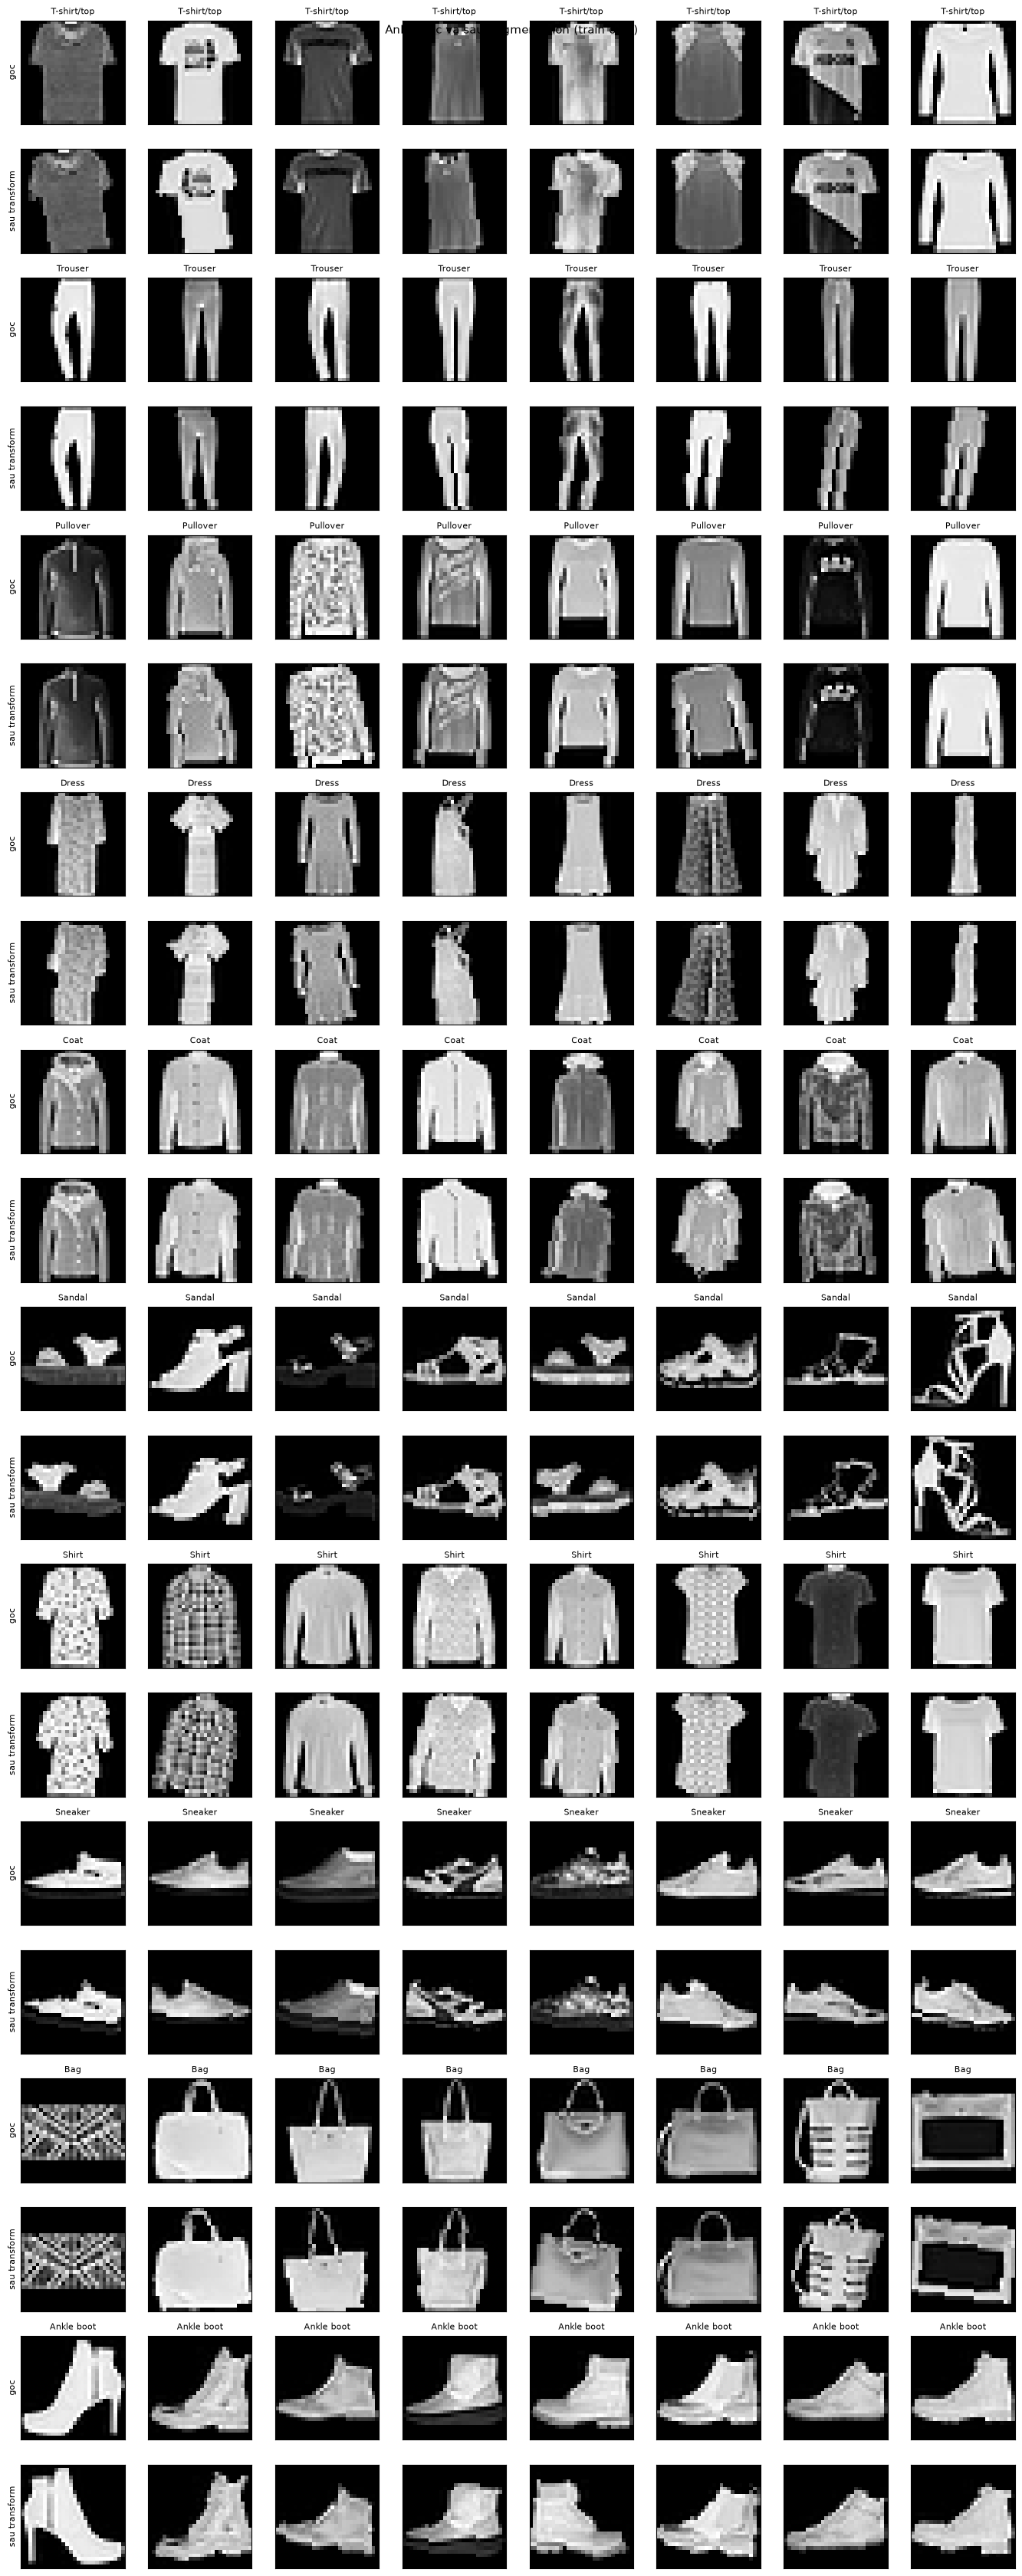

In [11]:
# Chuoi nay dung de VE, khong dung de train: giu nguyen phep bien doi hinh hoc
# nhung bo Normalize. Neu ve bang train_tf, mang hien thi se chua gia tri da
# chuan hoa (mean 0.286, std 0.353), nam ngoai [0, 1], va bi cat mat chi tiet.
aug_preview_tf = transforms.Compose([
    transforms.ToPILImage(),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=10),
    transforms.ToTensor(),
])

picks = eda_mod.sample_images_per_class(X_tr_raw, y_pool[train_idx], CLASS_NAMES,
                                        n_per_class=8, seed=RANDOM_SEED)
fig = eda_mod.plot_augmentation_grid(
    X_tr_raw, picks, y_pool[train_idx], CLASS_NAMES, aug_preview_tf,
    save_path=FIGURES_DIR / "augmentation_examples.png",
)
plt.show()
plt.show()

In [12]:
twice = [eval_tf(X_tr_raw[0]) for _ in range(2)]
guard("eval transform is deterministic",
      bool(torch.equal(twice[0], twice[1])))
guard("augmented output is a tensor with 1 channel",
      tuple(train_tf(X_tr_raw[0]).shape) == (1, *X_tr_raw.shape[1:]),
      str(tuple(train_tf(X_tr_raw[0]).shape)))

[PASS] eval transform is deterministic
[PASS] augmented output is a tensor with 1 channel | (1, 28, 28)


True

## F7. Kiểm tra data contract của loader

Loader là nơi dễ xảy ra lỗi shape và lỗi lan augmentation nhất. Kiểm tra cả shape,
dtype, khoảng giá trị, và tính tất định của nhánh validation.

In [13]:
from src.dataset import get_dataloaders

# get_dataloaders nhan co `augment`, khong nhan transform: no tu dung
# transforms cua src/dataset.py voi mean/std doc tu preprocessing_config.json.
# Truyen transform vao day se bi tu choi vi loader la noi duy nhat quyet dinh
# chuoi bien doi, tranh truong hop train va eval dung hai chuoi khac nhau.
train_loader, val_loader, test_loader, classes = get_dataloaders(
    batch_size=64, num_workers=0, split_dir=EDA_DIR, augment=True,
)
guard("loader returned the expected class names",
      list(classes) == list(CLASS_NAMES), str(classes))
guard("train loader covers the train partition",
      len(train_loader.dataset) == split_meta["train_size"],
      f"{len(train_loader.dataset)} vs {split_meta['train_size']}")

for name, loader in (("train", train_loader), ("val", val_loader), ("test", test_loader)):
    xb, yb = next(iter(loader))
    print(f"[{name}] x={tuple(xb.shape)} y={tuple(yb.shape)} "
          f"dtype={xb.dtype} range=[{xb.min():.3f}, {xb.max():.3f}]")
assert not guard_failures, f"Guards failed: {guard_failures}"

[PASS] loader returned the expected class names | ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat', 'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']
[PASS] train loader covers the train partition | 54000 vs 54000
[train] x=(64, 1, 28, 28) y=(64,) dtype=torch.float32 range=[-0.810, 2.021]
[val] x=(64, 1, 28, 28) y=(64,) dtype=torch.float32 range=[-0.810, 2.021]
[test] x=(64, 1, 28, 28) y=(64,) dtype=torch.float32 range=[-0.810, 2.021]


## F8. Xác nhận `src/config.py` đọc đúng artifact

Module config phải nạp mean/std từ file JSON vừa ghi, không rơi về hằng số dự
phòng. Nếu nguồn là `fallback:`, artifact chưa được đọc và mọi kết quả sau đó
không đáng tin.

In [14]:
import importlib
import src.config as config_mod
importlib.reload(config_mod)

print(f"[SOURCE] {config_mod.NORMALIZATION_SOURCE}")
print(f"[MEAN]   {config_mod.FASHION_MNIST_MEAN}")
print(f"[STD]    {config_mod.FASHION_MNIST_STD}")

guard("config read the artifact, not the fallback",
      config_mod.NORMALIZATION_SOURCE.startswith("artifact:"),
      config_mod.NORMALIZATION_SOURCE)
guard("config mean matches measurement",
      tuple(config_mod.FASHION_MNIST_MEAN) == MEAN,
      f"{config_mod.FASHION_MNIST_MEAN} vs {MEAN}")
guard("config std matches measurement",
      tuple(config_mod.FASHION_MNIST_STD) == STD,
      f"{config_mod.FASHION_MNIST_STD} vs {STD}")
assert not guard_failures, f"Guards failed: {guard_failures}"

[SOURCE] artifact:C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\preprocessing_config.json
[MEAN]   (0.286209,)
[STD]    (0.35316,)
[PASS] config read the artifact, not the fallback | artifact:C:\Users\Win 11\Documents\Lab DL\labs\lab01\outputs\eda\preprocessing_config.json
[PASS] config mean matches measurement | (0.286209,) vs (0.286209,)
[PASS] config std matches measurement | (0.35316,) vs (0.35316,)


## F9. Bảng khóa cấu hình cuối cùng

Bảng này là bản ghi để đối chiếu với walkthrough. Mọi run training phải dùng đúng
cấu hình ở đây, kèm `split_version` và `preproc_version`.

In [15]:
summary = pd.DataFrame([
    {"item": "split_version", "value": split_meta["split_version"]},
    {"item": "preproc_version", "value": PREPROC_VERSION},
    {"item": "train_size", "value": split_meta["train_size"]},
    {"item": "val_size", "value": split_meta["val_size"]},
    {"item": "mean", "value": str(MEAN)},
    {"item": "std", "value": str(STD)},
    {"item": "normalized_std", "value": f"{float(normalized.std()):.6f}"},
    {"item": "augmentation", "value": "horizontal_flip + rotation(10)"},
])
summary.to_csv(TABLES_DIR / "preprocessing_summary.csv", index=False)
display(summary)

,item,value
0,split_version,split_v2_stratified
1,preproc_version,preproc_v2_train_global_std
2,train_size,54000
3,val_size,6000
4,mean,"(0.286209,)"
5,std,"(0.35316,)"
6,normalized_std,1.003188
7,augmentation,horizontal_flip + rotation(10)


## F10. Bàn giao sang notebook training

Notebook training phải assert bốn điều kiện trước khi train: artifact tồn tại,
`preproc_version` khớp `split_version`, mean/std nạp từ `artifact:`, và kích thước
loader khớp metadata. Một guard chỉ `print` sẽ bị bỏ qua khi chạy batch.

In [16]:
handoff = {
    "split_version": split_meta["split_version"],
    "preproc_version": PREPROC_VERSION,
    "mean": list(MEAN),
    "std": list(STD),
    "normalized_std": round(float(normalized.std()), 6),
    "train_size": split_meta["train_size"],
    "val_size": split_meta["val_size"],
    "config_path": str(PREPROCESSING_CONFIG_PATH),
}
out = EDA_DIR / "feature_engineering_summary.json"
out.write_text(json.dumps(handoff, indent=2), encoding="utf-8")
print(json.dumps(handoff, indent=2))

{
  "split_version": "split_v2_stratified",
  "preproc_version": "preproc_v2_train_global_std",
  "mean": [
    0.286209
  ],
  "std": [
    0.35316
  ],
  "normalized_std": 1.003188,
  "train_size": 54000,
  "val_size": 6000,
  "config_path": "C:\\Users\\Win 11\\Documents\\Lab DL\\labs\\lab01\\outputs\\eda\\preprocessing_config.json"
}
